# V3: Trực quan hóa ERP, Scalp Topomap & Kiểm tra P300 (Polich 2007)

In [2]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import mne
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if (ROOT / "src").is_dir():
    pass
elif (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.erp.plot_erp import (
    load_subject_epochs,
    compute_evokeds,
    plot_midline_erp,
    plot_fz_pz_erp,
    plot_difference_waves,
    plot_erp_topomap,
    plot_p300_summary_topomap,
    plot_grand_average_erp,
    plot_population_summary,
    verify_p300,
    print_verification_summary,
    export_group_p300_table,
    run_subject_erp_analysis,
    run_group_erp_analysis
)
from config import FIG_DIR, TABLE_DIR

mne.set_log_level("ERROR")
SUB = "sub-01"

## 1. Kiểm chứng P300 của dự án

Biên độ 300–500 ms; đỉnh tìm độc lập trong 200–800 ms. Ba tiêu chí lõi P3b và xu hướng P3a mô tả không phải ngưỡng chẩn đoán của Polich.


In [3]:
epochs = load_subject_epochs(SUB)
report = verify_p300(epochs, SUB)
print_verification_summary(report)

       KIỂM CHỨNG P300 THEO TIÊU CHÍ DỰ ÁN – sub-01
Số lượng trial: {'standard': 479, 'target': 61, 'distractor': 51}
--------------------------------------------------------------------
1. Biên độ trung bình cửa sổ 300-500 ms (µV):
   Kênh  |    Standard    |     Target     |   Distractor   | Hiệu (T - S)
   Fz    |        -3.20 µV |        -6.67 µV |        -5.59 µV |      -3.47 µV
   Cz    |        -1.08 µV |        -1.00 µV |        -1.15 µV |       0.08 µV
   Pz    |         1.56 µV |         5.68 µV |         4.81 µV |       4.12 µV
--------------------------------------------------------------------
2. Đỉnh Target P3b (tìm trong 200-800 ms):
   Fz: Biên độ đỉnh =  0.95 µV | Độ trễ đỉnh = 200.0 ms
   Cz: Biên độ đỉnh =  3.51 µV | Độ trễ đỉnh = 780.0 ms
   Pz: Biên độ đỉnh = 10.88 µV | Độ trễ đỉnh = 580.0 ms
--------------------------------------------------------------------
3. Tiêu chí dự án dựa trên khung P3a/P3b (Polich, 2007):
   [PASS] Gradient vùng đỉnh (Pz > Fz) : Pz (5.68

## 2. ERP đường giữa (Fz, Cz, Pz)

  -> Saved Midline ERP figure: /home/armordkay/git clone/EEG/results/figures/sub-01_midline_erp.png
  -> Saved Midline ERP figure: /home/armordkay/git clone/EEG/results/figures/sub-01_fz_pz_erp.png


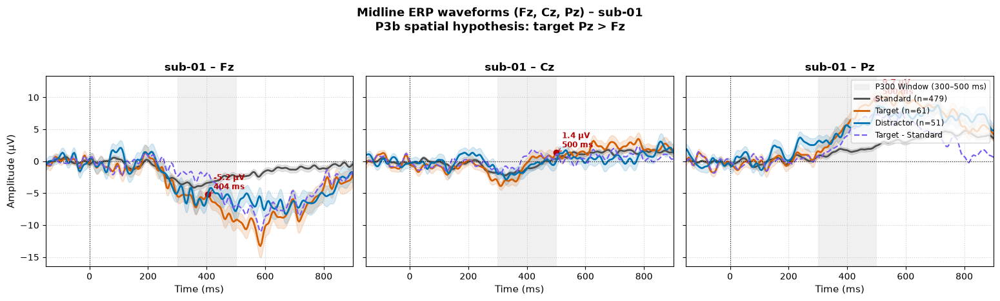

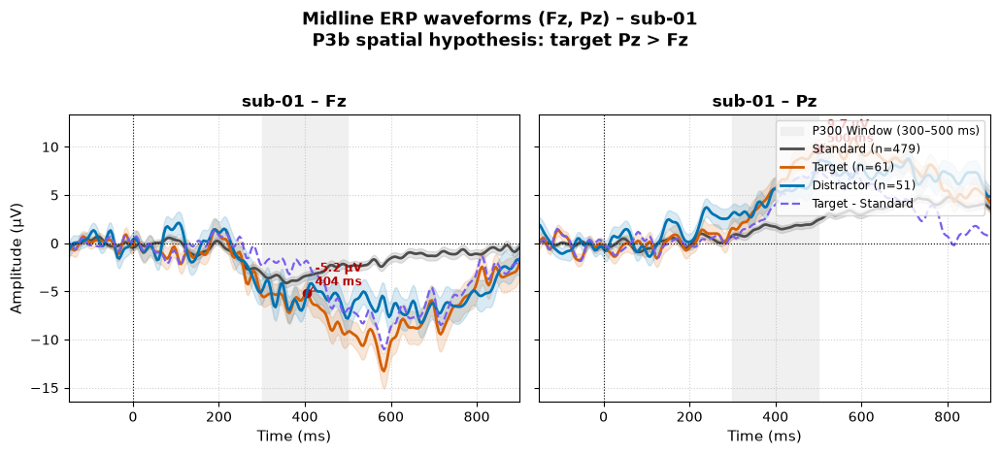

In [4]:
fig_midline = plot_midline_erp(epochs, SUB, save_path=FIG_DIR / f"{SUB}_midline_erp.png")
fig_fzpz = plot_fz_pz_erp(epochs, SUB, save_path=FIG_DIR / f"{SUB}_fz_pz_erp.png")
plt.show()

## 3. Sóng hiệu số (Difference Waves: P3a vs P3b)

  -> Saved Difference Waves figure: /home/armordkay/git clone/EEG/results/figures/sub-01_difference_waves.png


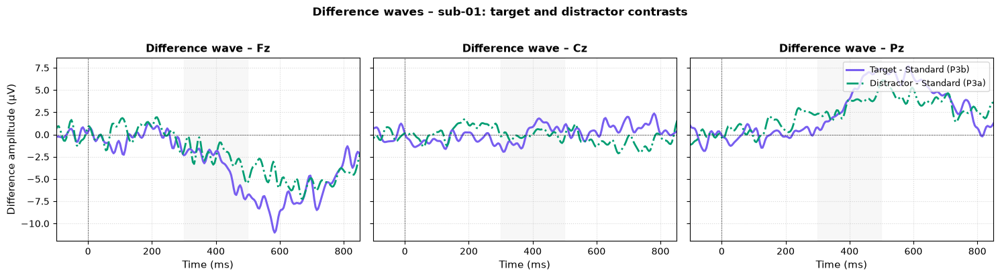

In [5]:
fig_diff = plot_difference_waves(epochs, SUB, save_path=FIG_DIR / f"{SUB}_difference_waves.png")
plt.show()

## 4. Scalp Topomap 128 kênh theo thời gian

  -> Saved Scalp Topomap figure: /home/armordkay/git clone/EEG/results/figures/sub-01_scalp_topomap.png


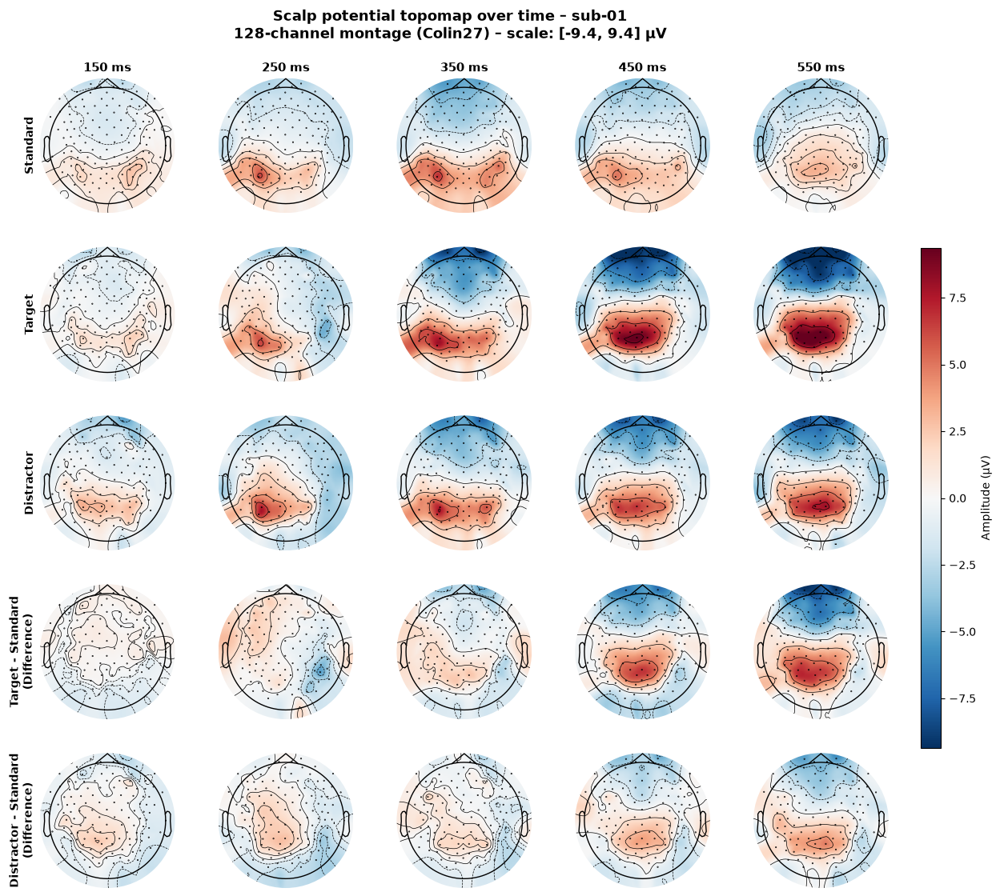

In [6]:
fig_topo = plot_erp_topomap(epochs, SUB, times=(0.15, 0.25, 0.35, 0.45, 0.55), save_path=FIG_DIR / f"{SUB}_scalp_topomap.png")
plt.show()

## 5. Topomap trung bình cửa sổ P300 (300-500 ms)

  -> Saved Summary Topomap figure: /home/armordkay/git clone/EEG/results/figures/sub-01_p300_summary_topomap.png


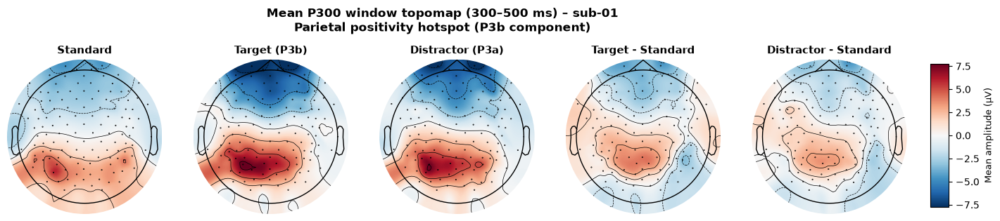

In [7]:
fig_summary = plot_p300_summary_topomap(epochs, SUB, window=(0.3, 0.5), save_path=FIG_DIR / f"{SUB}_p300_summary_topomap.png")
plt.show()

## 6. Chạy phân tích nhóm một lần cho 42 người

Giữ trial đúng; trung bình và topomap cho 39 người có trọng số bằng nhau. Đồng thời xuất bảng 300–500 ms, phân tích bổ sung 300–600 ms và thống kê. QC cũ vẫn mô tả 300–600 ms trên tất cả trial.


[sub-01] ERP analysed; correct trials: {'standard': 479, 'target': 61, 'distractor': 51}
[sub-02] ERP analysed; correct trials: {'standard': 475, 'target': 79, 'distractor': 1}
[sub-03] ERP analysed; correct trials: {'standard': 475, 'target': 81, 'distractor': 70}
[sub-04] ERP analysed; correct trials: {'standard': 498, 'target': 79, 'distractor': 76}
[sub-05] ERP analysed; correct trials: {'standard': 489, 'target': 79, 'distractor': 68}
[sub-06] ERP analysed; correct trials: {'standard': 482, 'target': 75, 'distractor': 75}
[sub-07] ERP analysed; correct trials: {'standard': 238, 'target': 37, 'distractor': 34}
[sub-08] ERP analysed; correct trials: {'standard': 492, 'target': 69, 'distractor': 67}
[sub-09] ERP analysed; correct trials: {'standard': 495, 'target': 68, 'distractor': 74}
[sub-10] ERP analysed; correct trials: {'standard': 485, 'target': 67, 'distractor': 48}
[sub-11] ERP analysed; correct trials: {'standard': 494, 'target': 81, 'distractor': 80}
[sub-12] ERP analysed;

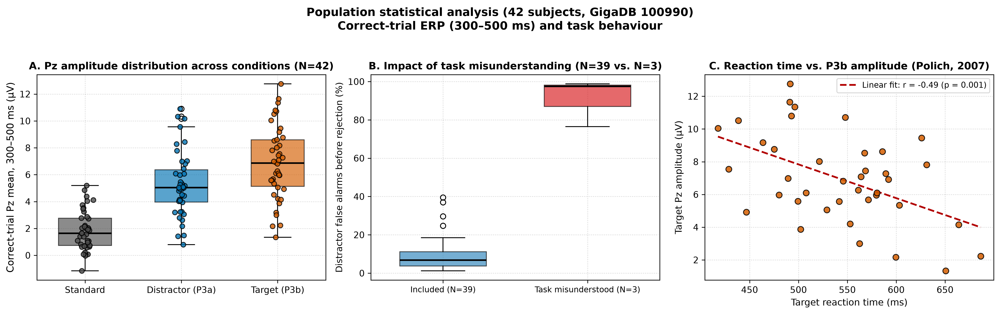

In [8]:
group_summary = run_group_erp_analysis(FIG_DIR)
group_df = pd.read_csv(TABLE_DIR / "v3_p300_group_results.csv")
display(Image(filename=str(FIG_DIR / "population_p300_summary.png")))


## 7. Grand Average ERP (Fz, Pz – Slide & Báo cáo)

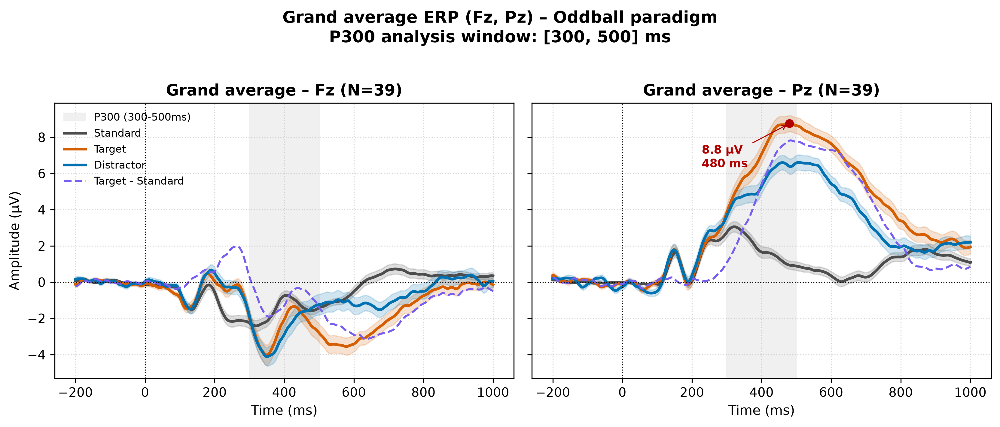

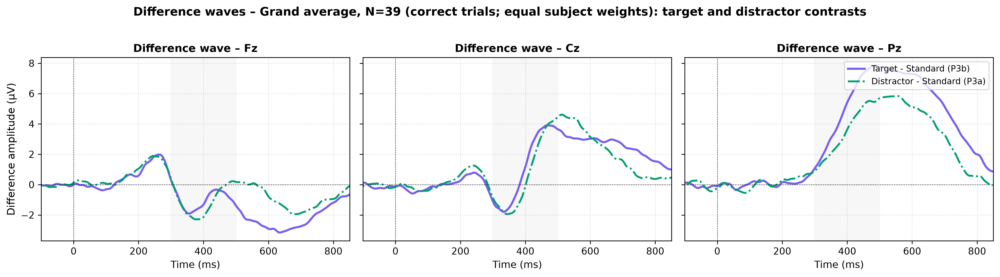

In [9]:
display(Image(filename=str(FIG_DIR / "grand_average_fz_pz.png")))
display(Image(filename=str(FIG_DIR / "grand_average_difference_waves.png")))


## 8. Bảng Tổng hợp Kết quả Kiểm chứng P300 Toàn bộ Nhóm (42 Đối tượng)

In [10]:
display(group_df)
included = group_df[group_df["group"] == "Normal"]
print(f"Ba tiêu chí lõi 300–500 ms: {included['p300_detected'].sum()}/{len(included)}")
print(f"Phân tích bổ sung 300–600 ms: {included['p300_detected_300_600'].sum()}/{len(included)}")


,subject,group,task_misunderstood,analysis_start_ms,analysis_end_ms,peak_search_start_ms,peak_search_end_ms,pz_target_uv,pz_standard_uv,pz_distractor_uv,...,p300_detected_300_600,n_standard_correct,n_target_correct,n_distractor_correct,target_rt_ms,false_alarm_distractor_pct,target_omission_pct,pz_standard_300_600_uv,pz_target_300_600_uv,pz_distractor_300_600_uv
0,sub-01,Normal,False,300.0,500.0,200.0,800.0,5.679149,1.561347,4.811749,...,True,479,61,51,571.5,37.04,23.46,2.041343,7.040617,5.767518
1,sub-02,Task-Misunderstood,True,300.0,500.0,200.0,800.0,8.168020,0.806114,2.166175,...,True,475,79,1,385.2,98.77,0.00,0.817720,7.091391,0.547801
2,sub-03,Normal,False,300.0,500.0,200.0,800.0,6.099751,0.070779,3.246088,...,True,475,81,70,507.7,12.35,0.00,0.189237,6.579601,3.090247
3,sub-04,Normal,False,300.0,500.0,200.0,800.0,4.204490,1.060864,2.622585,...,True,498,79,76,552.9,6.17,2.47,1.149359,4.557243,3.090833
4,sub-05,Normal,False,300.0,500.0,200.0,800.0,7.542079,1.096894,5.172183,...,True,489,79,68,428.6,9.88,0.00,0.426253,6.957840,6.089921
5,sub-06,Normal,False,300.0,500.0,200.0,800.0,5.957241,1.408811,5.238534,...,True,482,75,75,579.6,3.70,3.70,0.595276,6.921315,5.654400
6,sub-07,Normal,False,300.0,500.0,200.0,800.0,2.236211,0.084378,1.479816,...,True,238,37,34,686.4,29.63,39.51,-0.088723,3.031580,2.010166
7,sub-08,Normal,False,300.0,500.0,200.0,800.0,6.265048,3.251999,5.347929,...,False,492,69,67,561.3,14.81,14.81,2.743174,6.883093,5.854265
8,sub-09,Normal,False,300.0,500.0,200.0,800.0,6.912965,0.214682,3.944065,...,True,495,68,74,592.2,8.64,12.35,-0.227665,6.929120,4.157302
9,sub-10,Normal,False,300.0,500.0,200.0,800.0,6.820998,0.629055,3.058308,...,False,485,67,48,545.8,39.51,17.28,0.363681,8.197830,3.977099


Ba tiêu chí lõi 300–500 ms: 22/39
Phân tích bổ sung 300–600 ms: 32/39


## 9. Topomap 39 người (không phải ví dụ sub-01)


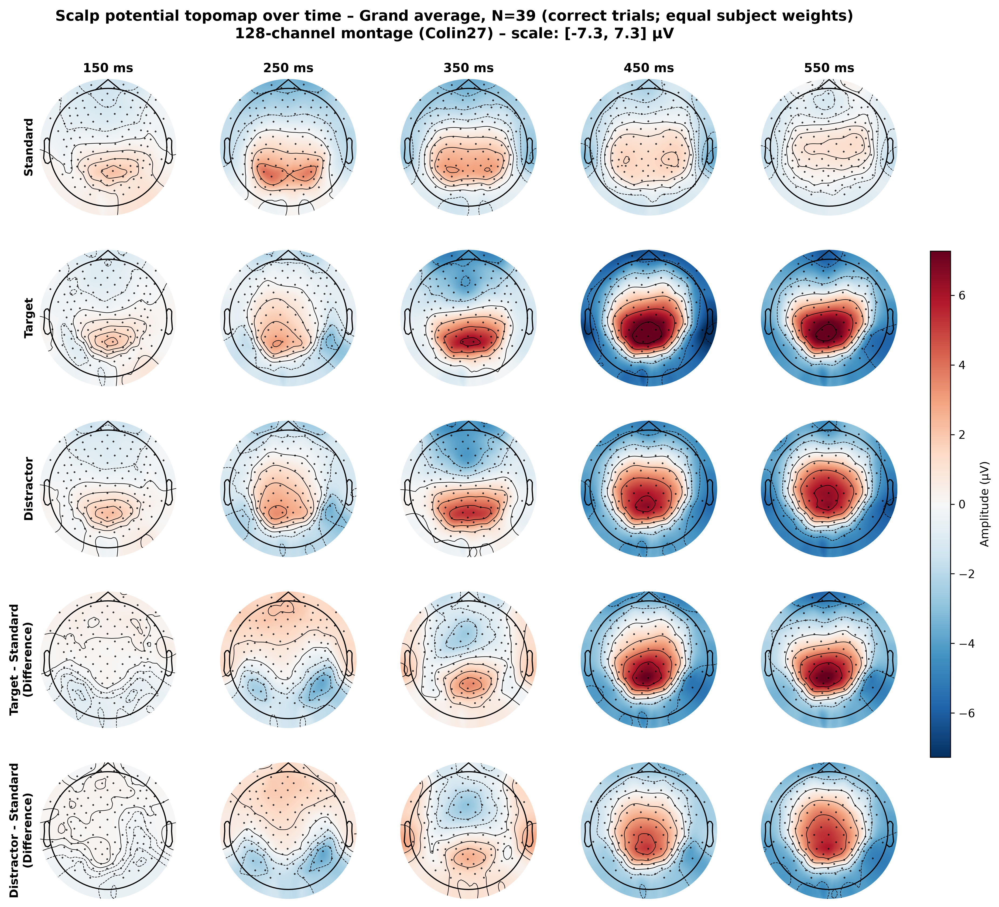

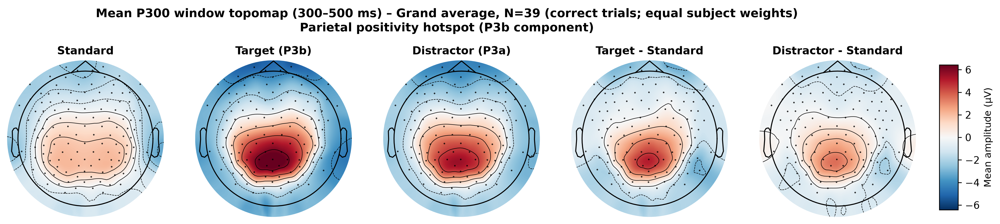

In [11]:
display(Image(filename=str(FIG_DIR / "grand_average_scalp_topomap.png")))
display(Image(filename=str(FIG_DIR / "grand_average_p300_summary_topomap.png")))
